In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)




###Reading Data

In [16]:
df=pd.read_csv(r"/content/german_credit_data.csv",encoding="latin-1")

In [17]:
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,0,67,male,2,own,NaN,little,1169,6,radio/TV
1,1,22,female,2,own,little,moderate,5951,48,radio/TV
2,2,49,male,1,own,little,NaN,2096,12,education
3,3,45,male,2,free,little,little,7882,42,furniture/equipment
4,4,53,male,2,free,little,little,4870,24,car


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        1000 non-null   int64 
 1   Age               1000 non-null   int64 
 2   Sex               1000 non-null   object
 3   Job               1000 non-null   int64 
 4   Housing           1000 non-null   object
 5   Saving accounts   817 non-null    object
 6   Checking account  606 non-null    object
 7   Credit amount     1000 non-null   int64 
 8   Duration          1000 non-null   int64 
 9   Purpose           1000 non-null   object
dtypes: int64(5), object(5)
memory usage: 78.3+ KB


In [19]:
df.drop("Unnamed: 0",inplace=True,axis=1)

In [20]:
df.nunique()

,0
Age,53
Sex,2
Job,4
Housing,3
Saving accounts,4
Checking account,3
Credit amount,921
Duration,33
Purpose,8


In [21]:
df.describe(include="all")

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
count,1000.000000,1000,1000.000000,1000,817,606,1000.000000,1000.000000,1000
unique,NaN,2,NaN,3,4,3,NaN,NaN,8
top,NaN,male,NaN,own,little,little,NaN,NaN,car
freq,NaN,690,NaN,713,603,274,NaN,NaN,337
mean,35.546000,NaN,1.904000,NaN,NaN,NaN,3271.258000,20.903000,NaN
std,11.375469,NaN,0.653614,NaN,NaN,NaN,2822.736876,12.058814,NaN
min,19.000000,NaN,0.000000,NaN,NaN,NaN,250.000000,4.000000,NaN
25%,27.000000,NaN,2.000000,NaN,NaN,NaN,1365.500000,12.000000,NaN
50%,33.000000,NaN,2.000000,NaN,NaN,NaN,2319.500000,18.000000,NaN
75%,42.000000,NaN,2.000000,NaN,NaN,NaN,3972.250000,24.000000,NaN


In [22]:

for col in df.select_dtypes(include="object"):
  print (col,':',df[col].unique())

Sex : ['male' 'female']
Housing : ['own' 'free' 'rent']
Saving accounts : [nan 'little' 'quite rich' 'rich' 'moderate']
Checking account : ['little' 'moderate' nan 'rich']
Purpose : ['radio/TV' 'education' 'furniture/equipment' 'car' 'business'
 'domestic appliances' 'repairs' 'vacation/others']


In [23]:
df.duplicated().sum()

np.int64(0)

###Data Analysis

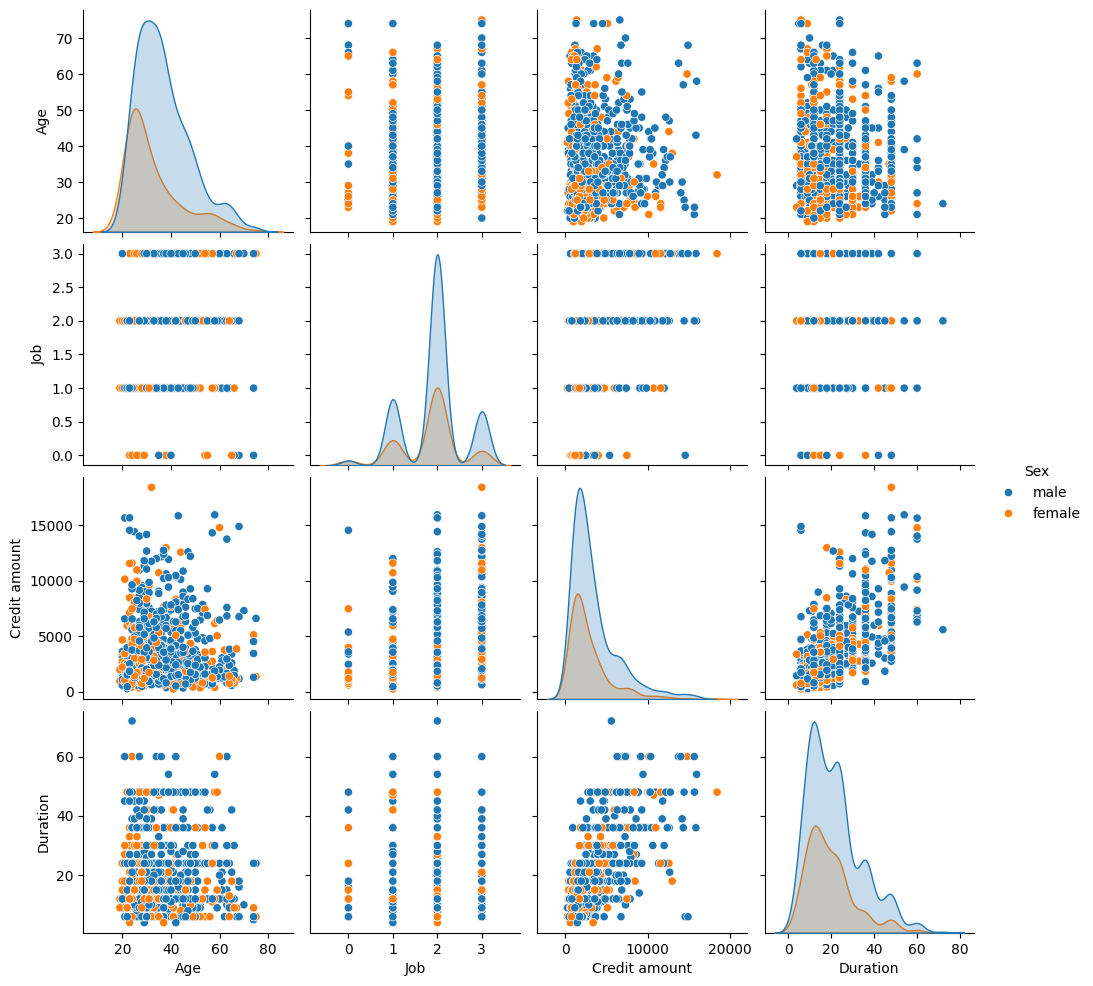

In [24]:
sns.pairplot(df,hue="Sex")

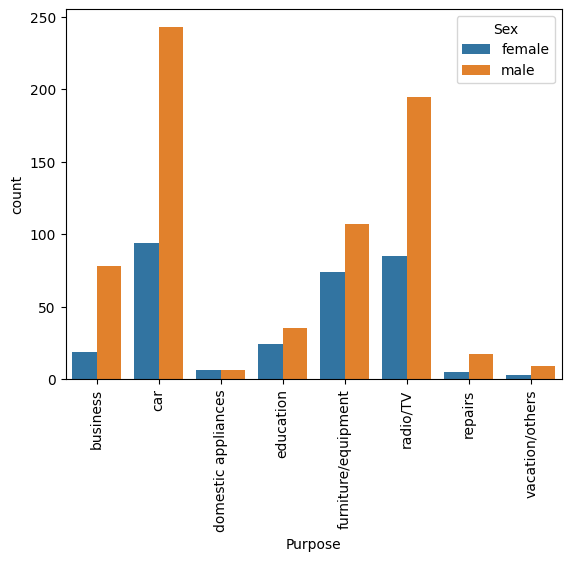

In [25]:
purpose_sex=df.groupby(["Purpose","Sex"]).size().reset_index(name="count")
sns.barplot(data=purpose_sex , x="Purpose",y="count",hue="Sex")
plt.xticks(rotation=90)
plt.show()

###Detect outliers

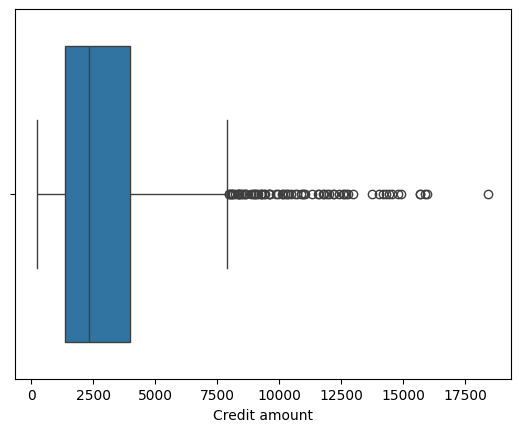

In [26]:
sns.boxplot(data=df,x="Credit amount")
plt.show()

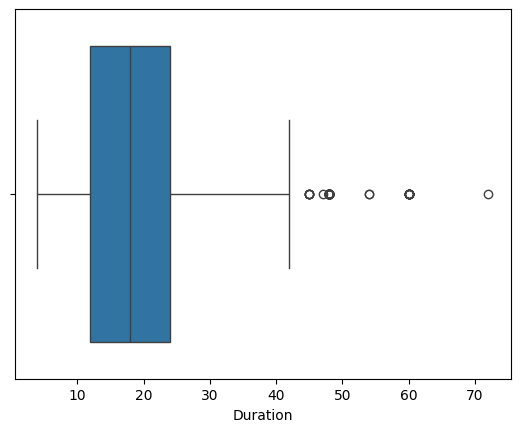

In [27]:
sns.boxplot(data=df,x="Duration")
plt.show()

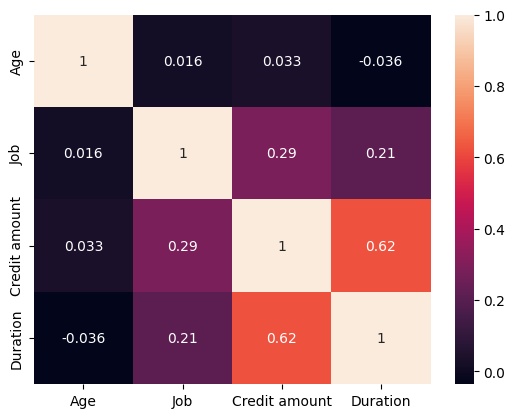

In [28]:
numerical_cols = df.select_dtypes(exclude=np.object_)
numerical_cols.head()
sns.heatmap(numerical_cols.corr(), annot=True)
plt.show()

###ُExtracting Features

In [29]:
cluster_sel=["Age","Credit amount","Duration"]
cluster_data = df.loc[:,cluster_sel]
cluster_data.head()

,Age,Credit amount,Duration
0,67,1169,6
1,22,5951,48
2,49,2096,12
3,45,7882,42
4,53,4870,24


###Scaling

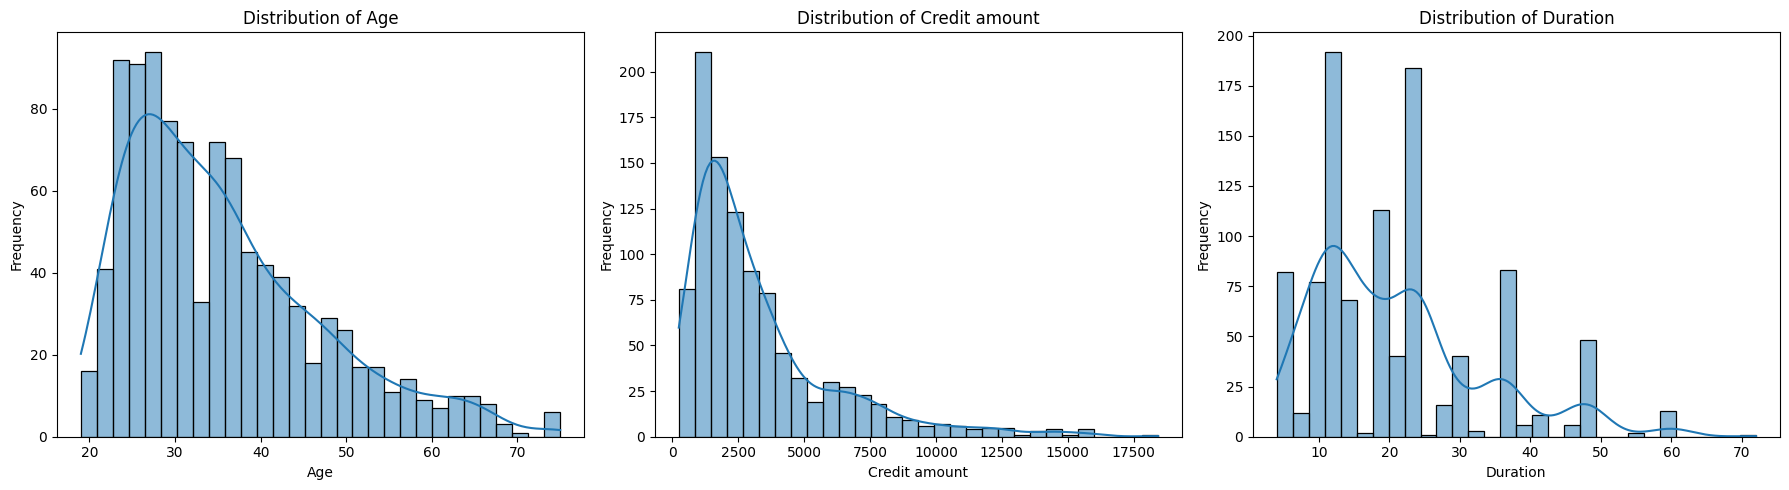

In [30]:
def plot_histograms(df):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, col in zip(axes, cluster_sel):
        sns.histplot(data=df, x=col, bins=30, kde=True, ax=ax)
        ax.set_title(f'Distribution of {col}')
        ax.set_xlabel(col)
        ax.set_ylabel('Frequency')

    plt.tight_layout()
    plt.show()

plot_histograms(df)


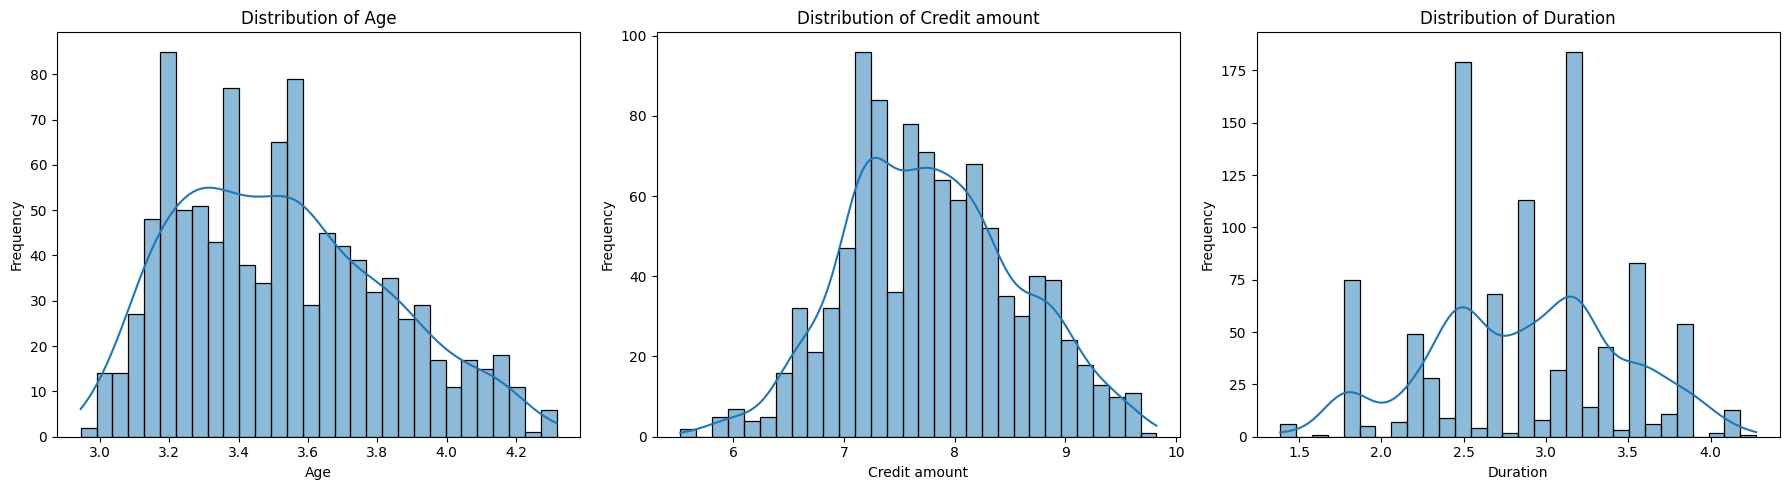

In [31]:
cluster_log = np.log(cluster_data)
plot_histograms(cluster_log)

In [32]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_log)
cluster_scaled

array([[ 2.27100592, -0.933901  , -1.86486906],
       [-1.44615223,  1.16304581,  1.7083687 ],
       [ 1.22669602, -0.1815588 , -0.67378981],
       ...,
       [ 0.37810951, -1.4161991 , -0.67378981],
       [-1.29778048, -0.34591111,  1.59746802],
       [-0.76258638,  0.82450846,  1.59746802]])

###KMeans

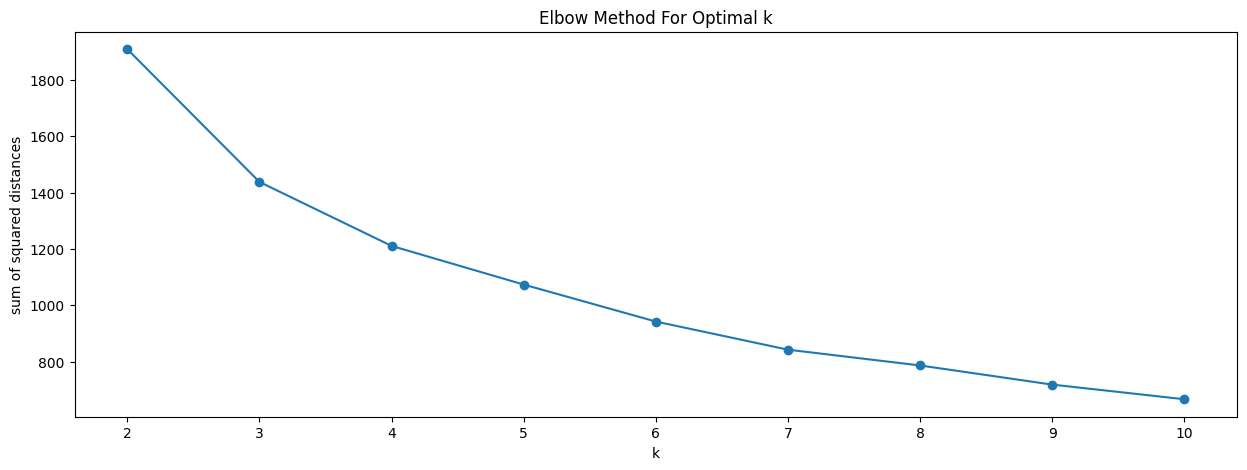

In [33]:
from sklearn.cluster import KMeans
result =[]
k_values = range(2,11)
for k in k_values:
     k_means=KMeans(n_clusters=k,random_state=42)
     k_means =k_means.fit(cluster_scaled)
     result.append(k_means.inertia_)
plt.figure(figsize = (15,5))
plt.plot(k_values,result,marker="o")
plt.xlabel("k")
plt.ylabel("sum of squared distances")
plt.title("Elbow Method For Optimal k")
plt.show()



###Silhouette

for n_clusters = 2, silhoutte score is 0.3152636489767985
for n_clusters = 3, silhoutte score is 0.3033583951666899
for n_clusters = 4, silhoutte score is 0.2725158075885455
for n_clusters = 5, silhoutte score is 0.2663870097934509
for n_clusters = 6, silhoutte score is 0.24348501118008598
for n_clusters = 7, silhoutte score is 0.25533587624426435
for n_clusters = 8, silhoutte score is 0.2421032774762369
for n_clusters = 9, silhoutte score is 0.2536613667875956
for n_clusters = 10, silhoutte score is 0.2552338503021205


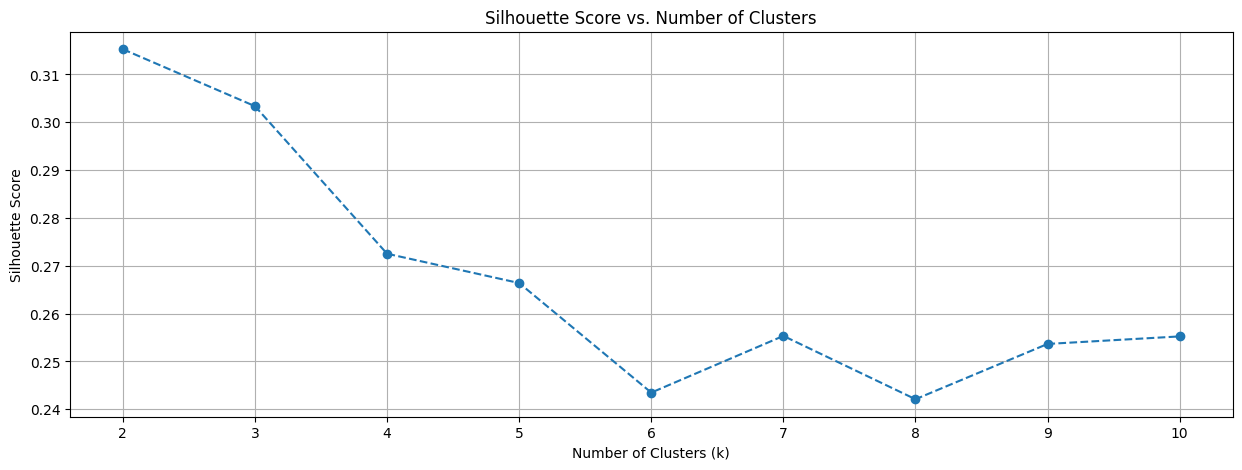

In [49]:
from sklearn.metrics import silhouette_score
silhouette_scores = []
k_values = range(2, 11)
for k in k_values:
  km= KMeans(n_clusters=k , random_state=1)
  km.fit(cluster_scaled)
  silhouette_scores.append(silhouette_score(cluster_scaled, km.labels_))
  print("for n_clusters = {}, silhoutte score is {}".format(k,silhouette_score(cluster_scaled,km.labels_)))
plt.figure(figsize=(15,5))
plt.plot(k_values,silhouette_scores, marker='o', linestyle='--')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs. Number of Clusters")
plt.grid(True)

###pred

In [53]:
kmeans_sel = KMeans(n_clusters=3, random_state=1).fit(cluster_scaled)
labels = pd.DataFrame(kmeans_sel.labels_)
clustered_data = cluster_data.assign(Cluster=labels)

In [54]:
clustered_data

,Age,Credit amount,Duration,Cluster
0,67,1169,6,1
1,22,5951,48,0
2,49,2096,12,1
3,45,7882,42,0
4,53,4870,24,0
5,35,9055,36,0
6,53,2835,24,1
7,35,6948,36,0
8,61,3059,12,1
9,28,5234,30,0


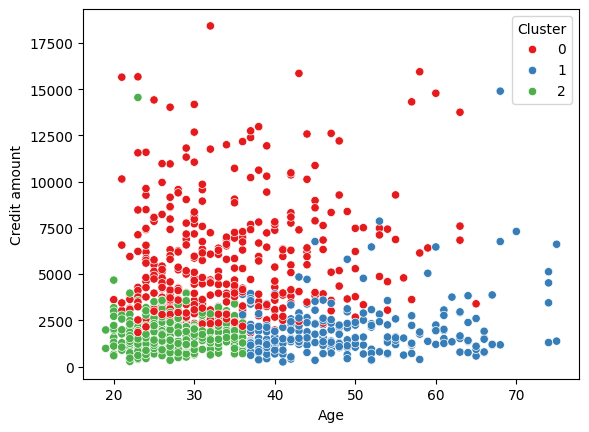

In [61]:
sns.scatterplot(data=clustered_data,x="Age",y="Credit amount", hue="Cluster",palette="Set1")

plt.show()

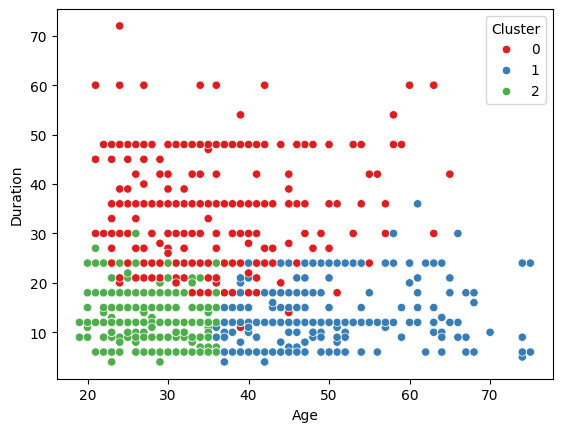

In [62]:
sns.scatterplot(data=clustered_data,x="Age",y="Duration", hue="Cluster",palette="Set1")

plt.show()

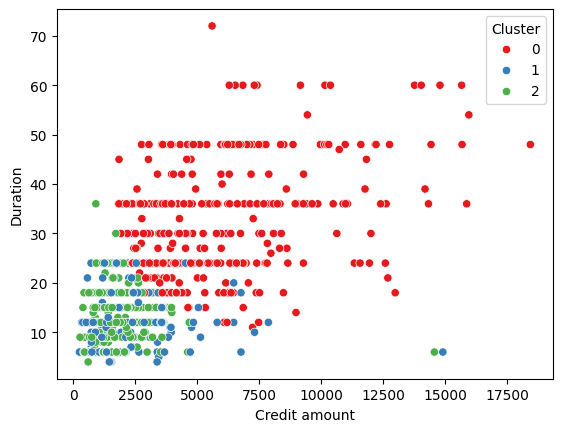

In [63]:
sns.scatterplot(data=clustered_data,y="Duration",x="Credit amount", hue="Cluster",palette="Set1")

plt.show()

In [64]:
grouped_km = clustered_data.groupby(['Cluster']).mean().round(1)
grouped_km

,Age,Credit amount,Duration
Cluster,,,
0,34.0,5665.4,32.2
1,48.7,1978.7,13.9
2,27.8,1733.6,14.2


In [67]:
cluster_profile = clustered_data.groupby("Cluster")[["Age", "Credit amount", "Duration"]].agg(["mean", "median"]).round(1)
cluster_profile

Age        Credit amount         Duration       
         mean median          mean  median     mean median
Cluster                                                   
0        34.0   32.0        5665.4  4686.0     32.2   30.0
1        48.7   47.0        1978.7  1523.0     13.9   12.0
2        27.8   27.0        1733.6  1505.0     14.2   12.0